# AG2 - Actividad Guiada 2

**Nombre:** Miguel Laversa

En esta actividad aplico programación dinámica, ramificación y poda y descenso del gradiente. Los ejemplos incluyen comprobaciones frente a métodos de referencia.

## 1. Viaje por el río - Programación dinámica

El coste mínimo entre dos embarcaderos se construye reutilizando costes ya calculados. El problema cumple el principio de optimalidad de Bellman y la tabla evita repetir subproblemas.

In [1]:
import math
import random
import time
from itertools import permutations

import matplotlib.pyplot as plt
import numpy as np

TARIFAS = [
    [0, 5, 4, 3, math.inf, math.inf, math.inf],
    [math.inf, 0, math.inf, 2, 3, math.inf, 11],
    [math.inf, math.inf, 0, 1, math.inf, 4, 10],
    [math.inf, math.inf, math.inf, 0, 5, 6, 9],
    [math.inf, math.inf, math.inf, math.inf, 0, math.inf, 4],
    [math.inf, math.inf, math.inf, math.inf, math.inf, 0, 3],
    [math.inf, math.inf, math.inf, math.inf, math.inf, math.inf, 0],
]

def viaje_rio(tarifas):
    n = len(tarifas)
    costes = [fila[:] for fila in tarifas]
    siguiente = [[None] * n for _ in range(n)]
    for i in range(n):
        for j in range(i + 1, n):
            if math.isfinite(tarifas[i][j]):
                siguiente[i][j] = j
    # Se resuelven primero los trayectos cortos para reutilizarlos en los largos.
    for longitud in range(2, n + 1):
        for origen in range(n - longitud + 1):
            destino = origen + longitud - 1
            for intermedio in range(origen + 1, destino):
                candidato = costes[origen][intermedio] + costes[intermedio][destino]
                if candidato < costes[origen][destino]:
                    costes[origen][destino] = candidato
                    siguiente[origen][destino] = siguiente[origen][intermedio]
    return costes, siguiente

def reconstruir_ruta(siguiente, origen, destino):
    if siguiente[origen][destino] is None:
        return []
    ruta = [origen]
    while origen != destino:
        origen = siguiente[origen][destino]
        ruta.append(origen)
    return ruta

costes, siguiente = viaje_rio(TARIFAS)
print("Coste mínimo de 0 a 6:", costes[0][6])
print("Ruta óptima:", reconstruir_ruta(siguiente, 0, 6))

Coste mínimo de 0 a 6: 11
Ruta óptima: [0, 2, 5, 6]


La ruta obtenida es `0 → 2 → 5 → 6`, con coste total 11. La tabla requiere $O(n^2)$ de espacio y el cálculo tiene coste $O(n^3)$.

## 2. Asignación de tareas - Ramificación y poda

Cada nivel asigna una tarea a un agente. La cota inferior suma el coste parcial y el menor coste disponible para cada agente restante. Si la cota no mejora la mejor solución conocida, la rama se elimina.

In [2]:
import heapq

COSTES = [
    [11, 12, 18, 40],
    [14, 15, 13, 22],
    [11, 17, 19, 23],
    [17, 14, 20, 28],
]

def coste_asignacion(asignacion, costes):
    return sum(costes[agente][tarea] for agente, tarea in enumerate(asignacion))

def cota_inferior(asignacion, costes):
    usadas = set(asignacion)
    libres = set(range(len(costes))) - usadas
    cota = coste_asignacion(asignacion, costes)
    # Esta estimación es optimista porque permite reutilizar una tarea al calcularla.
    for agente in range(len(asignacion), len(costes)):
        cota += min(costes[agente][tarea] for tarea in libres)
    return cota

def ramificacion_y_poda(costes):
    n = len(costes)
    mejor_asignacion = tuple(range(n))
    mejor_coste = coste_asignacion(mejor_asignacion, costes)
    frontera = [(cota_inferior((), costes), ())]
    expandidos = 0

    while frontera:
        # La cola prioriza el nodo con la menor cota estimada.
        cota, asignacion = heapq.heappop(frontera)
        if cota >= mejor_coste:
            # Ninguna solución descendiente puede mejorar la mejor conocida.
            continue
        expandidos += 1
        agente = len(asignacion)
        for tarea in range(n):
            if tarea in asignacion:
                continue
            hija = asignacion + (tarea,)
            if len(hija) == n:
                coste = coste_asignacion(hija, costes)
                if coste < mejor_coste:
                    mejor_asignacion, mejor_coste = hija, coste
            else:
                cota_hija = cota_inferior(hija, costes)
                if cota_hija < mejor_coste:
                    heapq.heappush(frontera, (cota_hija, hija))
    return mejor_asignacion, mejor_coste, expandidos

def fuerza_bruta(costes):
    return min(
        ((asignacion, coste_asignacion(asignacion, costes))
         for asignacion in permutations(range(len(costes)))),
        key=lambda resultado: resultado[1],
    )

solucion_bnb = ramificacion_y_poda(COSTES)
solucion_bruta = fuerza_bruta(COSTES)
print("Ramificación y poda:", solucion_bnb)
print("Fuerza bruta:", solucion_bruta)
assert solucion_bnb[:2] == solucion_bruta

Ramificación y poda: ((0, 2, 3, 1), 61, 7)
Fuerza bruta: ((0, 2, 3, 1), 61)


## 3. Ejercicio adicional - Escalabilidad

Comparo ambas estrategias con matrices reproducibles. La fuerza bruta revisa $n!$ asignaciones; la poda sigue teniendo peor caso exponencial, pero puede descartar gran parte del árbol.

In [3]:
# La semilla fija permite repetir la comparación con las mismas matrices.
generador = random.Random(7)
resultados = []
for dimension in range(4, 10):
    matriz = [[generador.randint(1, 100) for _ in range(dimension)] for _ in range(dimension)]

    inicio = time.perf_counter()
    _, coste_bnb, expandidos = ramificacion_y_poda(matriz)
    tiempo_bnb = time.perf_counter() - inicio

    inicio = time.perf_counter()
    _, coste_bruto = fuerza_bruta(matriz)
    tiempo_bruto = time.perf_counter() - inicio

    assert coste_bnb == coste_bruto
    resultados.append((dimension, tiempo_bruto, tiempo_bnb, expandidos))

print(f"{'n':>2} {'Fuerza bruta (s)':>18} {'R. y poda (s)':>16} {'Nodos':>10}")
for n, bruto, bnb, nodos in resultados:
    print(f"{n:>2} {bruto:>18.6f} {bnb:>16.6f} {nodos:>10}")
print("Para n=10, la fuerza bruta tendría", math.factorial(10), "permutaciones.")

 n   Fuerza bruta (s)    R. y poda (s)      Nodos
 4           0.000016         0.000043          7
 5           0.000071         0.000083         11
 6           0.000439         0.000062          6
 7           0.003278         0.000343         29
 8           0.028113         0.000750         65
 9           0.264564         0.000711         49
Para n=10, la fuerza bruta tendría 3628800 permutaciones.


## 4. Descenso del gradiente

En cada iteración actualizo el punto mediante $x_{t+1}=x_t-\alpha\nabla f(x_t)$. Primero uso un paraboloide convexo, cuyo mínimo global está en `(0, 0)`.

Punto final: [ 7.06738826e-08 -5.30054119e-08]
Valor final: 7.804371375789992e-15


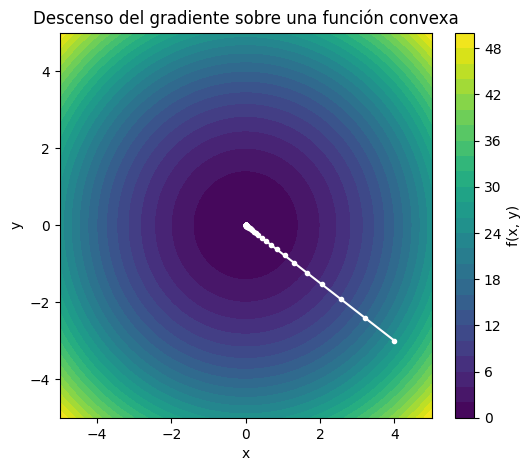

In [4]:
def descenso_gradiente(funcion, gradiente, inicial, tasa=0.1, iteraciones=80, tolerancia=1e-10):
    punto = np.array(inicial, dtype=float)
    trayectoria = [punto.copy()]
    for _ in range(iteraciones):
        nuevo = punto - tasa * np.asarray(gradiente(punto))
        trayectoria.append(nuevo.copy())
        # Se detiene cuando el desplazamiento deja de ser significativo.
        if np.linalg.norm(nuevo - punto) < tolerancia:
            punto = nuevo
            break
        punto = nuevo
    return punto, funcion(punto), np.array(trayectoria)

f_convexa = lambda p: p[0] ** 2 + p[1] ** 2
grad_convexa = lambda p: np.array([2 * p[0], 2 * p[1]])
punto, valor, trayectoria = descenso_gradiente(f_convexa, grad_convexa, [4, -3])
print("Punto final:", punto)
print("Valor final:", valor)

rejilla = np.linspace(-5, 5, 150)
X, Y = np.meshgrid(rejilla, rejilla)
Z = X ** 2 + Y ** 2
plt.figure(figsize=(6, 5))
plt.contourf(X, Y, Z, levels=30, cmap="viridis")
plt.plot(trayectoria[:, 0], trayectoria[:, 1], "o-", color="white", markersize=3)
plt.title("Descenso del gradiente sobre una función convexa")
plt.xlabel("x")
plt.ylabel("y")
plt.colorbar(label="f(x, y)")
plt.show()

### Función no convexa

La segunda función tiene varios mínimos locales. Aproximo el gradiente mediante diferencias centrales y ejecuto el algoritmo desde varios puntos para observar la dependencia respecto a la inicialización.

In [5]:
def f_no_convexa(p):
    x, y = p
    return math.sin(0.5 * x**2 - 0.25 * y**2 + 3) * math.cos(2*x + 1 - math.exp(y))

def gradiente_numerico(funcion, punto, h=1e-5):
    punto = np.asarray(punto, dtype=float)
    gradiente = np.zeros_like(punto)
    for i in range(len(punto)):
        # Las diferencias centrales reducen el error respecto a una diferencia hacia delante.
        avance = punto.copy(); avance[i] += h
        retroceso = punto.copy(); retroceso[i] -= h
        gradiente[i] = (funcion(avance) - funcion(retroceso)) / (2 * h)
    return gradiente

inicializaciones = [(-2, -1), (-1, 1), (0.5, -0.5), (1.5, 0.5)]
soluciones = []
for inicial in inicializaciones:
    punto, valor, trayectoria = descenso_gradiente(
        f_no_convexa,
        lambda p: gradiente_numerico(f_no_convexa, p),
        inicial,
        tasa=0.02,
        iteraciones=800,
    )
    soluciones.append((inicial, punto, valor))

for inicial, punto, valor in soluciones:
    print(f"Inicio={inicial}, final={np.round(punto, 5)}, f={valor:.6f}")

Inicio=(-2, -1), final=[-2.64513 -0.89213], f=-0.000200
Inicio=(-1, 1), final=[0.32271 1.6024 ], f=-0.657400
Inicio=(0.5, -0.5), final=[ 1.09965 -2.85223], f=-1.000000
Inicio=(1.5, 0.5), final=[2.20179 1.68706], f=-1.000000


Los puntos iniciales no convergen necesariamente al mismo mínimo. Este resultado muestra la diferencia entre optimizar una función convexa, donde el mínimo encontrado es global, y una función no convexa, donde el descenso puede quedar atrapado en mínimos locales.